In [ ]:
import itertools as it

from IPython.display import display
import marimo as mo
import numpy as np
import pandas as pd
import polars as pl
import seaborn as sns
from teeplot import teeplot as tp
from tqdm import tqdm
from watermark import watermark

from pylib._osf_fetch import osf_fetch
from pylib.theory._calc_mutator_fixprob_closed import (
    calc_mutator_fixprob_closed,
)
from pylib.viz._get_nben_cmap import get_nben_cmap
from pylib.viz._get_nben_hue_norm import get_nben_hue_norm
from pylib.viz._size_fixation_areaplot import size_fixation_areaplot
from pylib.viz._size_fixation_heatmap import size_fixation_heatmap

In [ ]:
mo.md(
    f"""
```Text
{watermark(
    current_date=True,
    iso8601=True,
    machine=True,
    updated=True,
    python=True,
    iversions=True,
    globals_=globals(),
)}
```
"""
)

```Text
Last updated: 2026-11-26T04:24:46.786295+00:00

Python implementation: CPython
Python version       : 3.10.22
IPython version      : 7.31.1

Compiler    : GCC 13.3.0
OS          : Linux
Release     : 7.0.0-1014-aws
Machine     : x86_64
Processor   : x86_64
CPU cores   : 4
Architecture: 64bit

seaborn: 0.13.2
teeplot: 1.2.0
marimo : 0.23.2
pandas : 2.2.3
numpy  : 2.1.2
polars : 1.9.0

```

In [ ]:
teeplot_subdir = "wse-5050-spatial2d-32atile-infben-traits"
teeplot_subdir

'wse-5050-spatial2d-32atile-infben-traits'

## Prep Data

In [ ]:
data = [
    {"url": "https://osf.io/p4tyb/download", "max ben muts": np.inf},
    {"url": "https://osf.io/93rdk/download", "max ben muts": 1},
    # {"url": "https://osf.io/fahu9/download", "max ben muts": 2},
    # {"url": "https://osf.io/2wxmb/download", "max ben muts": 3},
    # {"url": "https://osf.io/ra2fw/download", "max ben muts": 4},
    # {"url": "https://osf.io/6ek82/download", "max ben muts": 5},
]
dfs = []
for item in tqdm(data):
    df = pd.read_parquet(osf_fetch(item["url"]))
    df["available beneficial mutations"] = item["max ben muts"]
    df = pl.from_pandas(df)
    df = (
        df.with_columns(
            (pl.col("row").cast(pl.UInt64) // pl.col("nRowSubgrid")).alias(
                "rowGroup"
            ),
            (pl.col("col").cast(pl.UInt64) // pl.col("nColSubgrid")).alias(
                "colGroup"
            ),
        )
        .with_columns(
            (
                pl.col("colGroup")
                + (pl.col("colGroup").max() + 1) * pl.col("rowGroup")
            ).alias("group"),
        )
        .with_columns(
            (
                pl.col("trait value").replace_strict(
                    {0: "nonmutator", 1: "mutator"},
                )
            ).alias("genotype"),
        )
        .with_columns(
            (
                pl.col("nColSubgrid").cast(pl.UInt64)
                * pl.col("nRowSubgrid").cast(pl.UInt64)
                * pl.col("tilePopSize")
            ).alias("population size"),
        )
        .with_columns(
            (pl.col("trait count") / pl.col("tilePopSize")).alias(
                "fixation probability"
            ),
        )
    )
    dfs.append(
        df.group_by(
            [
                "group",
                "genotype",
                "replicate",
                "population size",
                "available beneficial mutations",
            ],
        ).agg(
            pl.col("fixation probability").mean(),
        ),
    )

  0%|          | 0/2 [00:00<?, ?it/s]

downloading https://osf.io/p4tyb/download -> /tmp/p4tyb
size: 49588576 bytes


 50%|█████     | 1/2 [00:07<00:07,  7.65s/it]

downloading https://osf.io/93rdk/download -> /tmp/93rdk
size: 53064508 bytes


100%|██████████| 2/2 [00:15<00:00,  7.53s/it]


In [ ]:
dfxs = pl.concat(dfs, how="vertical_relaxed").to_pandas()
dfxs["available\nbeneficial mutations"] = dfxs[
    "available beneficial mutations"
]
dfxs

,group,genotype,replicate,population size,available beneficial mutations,fixation probability,availablebeneficial mutations
0,94789.0,mutator,c4b6477c-e4b5-4612-a681-ec0a7f75fdf3,128.0,inf,0.0,inf
1,229915.0,nonmutator,274086c6-588e-4cba-a362-4b943b00b231,32.0,inf,0.0,inf
2,157191.0,nonmutator,274086c6-588e-4cba-a362-4b943b00b231,32.0,inf,0.0,inf
3,208642.0,nonmutator,274086c6-588e-4cba-a362-4b943b00b231,32.0,inf,0.0,inf
4,143067.0,nonmutator,274086c6-588e-4cba-a362-4b943b00b231,32.0,inf,1.0,inf
...,...,...,...,...,...,...,...
1398203,9981.0,mutator,0068d8b6-928a-46dd-8482-0d912b986e9e,128.0,1.0,0.0,1.0
1398204,202483.0,nonmutator,35e595e8-ddbf-4c9f-bf9b-bef42c0075cd,32.0,1.0,1.0,1.0
1398205,99408.0,nonmutator,35e595e8-ddbf-4c9f-bf9b-bef42c0075cd,32.0,1.0,0.0,1.0
1398206,3896.0,nonmutator,35e595e8-ddbf-4c9f-bf9b-bef42c0075cd,32.0,1.0,0.0,1.0


In [ ]:
apn = int(dfxs["population size"].min())  # agents per node
apn

32

In [ ]:
# math model predictions (see pylib/theory), for a 2D lattice of demes;
# the smallest population surveyed is a single deme
deme_size = int(dfxs["population size"].min())
model_N = np.geomspace(
    dfxs["population size"].min(), dfxs["population size"].max(), 60
)
model_xy = {
    float(K): (
        model_N.tolist(),
        [
            calc_mutator_fixprob_closed(N, K, deme_size=deme_size)
            for N in model_N
        ],
    )
    for K in sorted(dfxs["available beneficial mutations"].unique())
}

/home/runner/work/hypermutator-dynamics/hypermutator-dynamics/bindle/pylib/theory/_calc_drift_fixprob.py:15: RuntimeWarning: overflow encountered in expm1
  return float(np.expm1(a * x0) / np.expm1(a))


## Size Fixation Area Plots

In [ ]:
for _errorbar in "sd", "se", "ci", None:
    tp.tee(
        size_fixation_areaplot,
        fixprobs_df=dfxs,
        x="population size",
        y="fixation probability",
        hue="genotype",
        hue_order=["nonmutator", "mutator"],
        col="available\nbeneficial mutations",
        style="genotype",
        style_order=["nonmutator", "mutator"],
        errorbar=_errorbar,
        height=2,
        markers=True,
        teeplot_outexclude="post",
        teeplot_subdir=teeplot_subdir,
        teeplot_postprocess=f"""
teed.figure.suptitle("n={apn} agents per node", x=0.63, y=1.06)
teed.set_titles(col_template="{{col_var}} = {{col_name:.0f}}")
sns.move_legend(
    teed,
    "lower center",
    bbox_to_anchor=(0.25, 0.9),
    frameon=False,
    ncol=2,
    title=None,
)
""",
    )

/home/runner/work/hypermutator-dynamics/hypermutator-dynamics/bindle/pylib/viz/_size_fixation_areaplot.py:24: UserWarning: The palette list has more values (10) than needed (2), which may not be intended.
  g = sns.relplot(


teeplots/wse-5050-spatial2d-32atile-infben-traits/col=available-beneficial-mutations+errorbar=sd+hue=genotype+style=genotype+viz=size-fixation-areaplot+x=population-size+y=fixation-probability+ext=.pdf
teeplots/wse-5050-spatial2d-32atile-infben-traits/col=available-beneficial-mutations+errorbar=sd+hue=genotype+style=genotype+viz=size-fixation-areaplot+x=population-size+y=fixation-probability+ext=.png


/home/runner/work/hypermutator-dynamics/hypermutator-dynamics/bindle/pylib/viz/_size_fixation_areaplot.py:24: UserWarning: The palette list has more values (10) than needed (2), which may not be intended.
  g = sns.relplot(


teeplots/wse-5050-spatial2d-32atile-infben-traits/col=available-beneficial-mutations+errorbar=se+hue=genotype+style=genotype+viz=size-fixation-areaplot+x=population-size+y=fixation-probability+ext=.pdf
teeplots/wse-5050-spatial2d-32atile-infben-traits/col=available-beneficial-mutations+errorbar=se+hue=genotype+style=genotype+viz=size-fixation-areaplot+x=population-size+y=fixation-probability+ext=.png


/home/runner/work/hypermutator-dynamics/hypermutator-dynamics/bindle/pylib/viz/_size_fixation_areaplot.py:24: UserWarning: The palette list has more values (10) than needed (2), which may not be intended.
  g = sns.relplot(


teeplots/wse-5050-spatial2d-32atile-infben-traits/col=available-beneficial-mutations+errorbar=ci+hue=genotype+style=genotype+viz=size-fixation-areaplot+x=population-size+y=fixation-probability+ext=.pdf
teeplots/wse-5050-spatial2d-32atile-infben-traits/col=available-beneficial-mutations+errorbar=ci+hue=genotype+style=genotype+viz=size-fixation-areaplot+x=population-size+y=fixation-probability+ext=.png


/home/runner/work/hypermutator-dynamics/hypermutator-dynamics/bindle/pylib/viz/_size_fixation_areaplot.py:24: UserWarning: The palette list has more values (10) than needed (2), which may not be intended.
  g = sns.relplot(


teeplots/wse-5050-spatial2d-32atile-infben-traits/col=available-beneficial-mutations+hue=genotype+style=genotype+viz=size-fixation-areaplot+x=population-size+y=fixation-probability+ext=.pdf
teeplots/wse-5050-spatial2d-32atile-infben-traits/col=available-beneficial-mutations+hue=genotype+style=genotype+viz=size-fixation-areaplot+x=population-size+y=fixation-probability+ext=.png


In [ ]:
for (num_abm, fixprobs_df), _errorbar in it.product(
    dfxs.groupby(["available beneficial mutations"]),
    ("sd", "se", "ci", None),
):
    tp.tee(
        size_fixation_areaplot,
        fixprobs_df=fixprobs_df,
        x="population size",
        y="fixation probability",
        col=None,
        hue="genotype",
        hue_order=["nonmutator", "mutator"],
        style="genotype",
        style_order=["nonmutator", "mutator"],
        aspect=1.75,
        errorbar=_errorbar,
        height=2,
        markers=True,
        teeplot_outattrs={
            "num-abm": num_abm,
        },
        teeplot_outexclude="post",
        teeplot_subdir=teeplot_subdir,
        teeplot_postprocess=f"""
teed.figure.suptitle("n={apn} agents per node", x=0.42, y=1.06)
"""
        + f"""teed.ax.plot(
    *{model_xy[num_abm[0]]!r}, color="black", linestyle="--"
)
"""
        + "from pylib.viz._add_legend_entry import add_legend_entry\n"
        + 'add_legend_entry(teed, "analytic\\napprox")\n',
    )

/home/runner/work/hypermutator-dynamics/hypermutator-dynamics/bindle/pylib/viz/_size_fixation_areaplot.py:24: UserWarning: The palette list has more values (10) than needed (2), which may not be intended.
  g = sns.relplot(


teeplots/wse-5050-spatial2d-32atile-infben-traits/errorbar=sd+hue=genotype+num-abm=(1.0,)+style=genotype+viz=size-fixation-areaplot+x=population-size+y=fixation-probability+ext=.pdf
teeplots/wse-5050-spatial2d-32atile-infben-traits/errorbar=sd+hue=genotype+num-abm=(1.0,)+style=genotype+viz=size-fixation-areaplot+x=population-size+y=fixation-probability+ext=.png


/home/runner/work/hypermutator-dynamics/hypermutator-dynamics/bindle/pylib/viz/_size_fixation_areaplot.py:24: UserWarning: The palette list has more values (10) than needed (2), which may not be intended.
  g = sns.relplot(


teeplots/wse-5050-spatial2d-32atile-infben-traits/errorbar=se+hue=genotype+num-abm=(1.0,)+style=genotype+viz=size-fixation-areaplot+x=population-size+y=fixation-probability+ext=.pdf
teeplots/wse-5050-spatial2d-32atile-infben-traits/errorbar=se+hue=genotype+num-abm=(1.0,)+style=genotype+viz=size-fixation-areaplot+x=population-size+y=fixation-probability+ext=.png


/home/runner/work/hypermutator-dynamics/hypermutator-dynamics/bindle/pylib/viz/_size_fixation_areaplot.py:24: UserWarning: The palette list has more values (10) than needed (2), which may not be intended.
  g = sns.relplot(


teeplots/wse-5050-spatial2d-32atile-infben-traits/errorbar=ci+hue=genotype+num-abm=(1.0,)+style=genotype+viz=size-fixation-areaplot+x=population-size+y=fixation-probability+ext=.pdf
teeplots/wse-5050-spatial2d-32atile-infben-traits/errorbar=ci+hue=genotype+num-abm=(1.0,)+style=genotype+viz=size-fixation-areaplot+x=population-size+y=fixation-probability+ext=.png


... (6 outputs left out)

/home/runner/work/hypermutator-dynamics/hypermutator-dynamics/bindle/pylib/viz/_size_fixation_areaplot.py:24: UserWarning: The palette list has more values (10) than needed (2), which may not be intended.
  g = sns.relplot(


teeplots/wse-5050-spatial2d-32atile-infben-traits/errorbar=ci+hue=genotype+num-abm=(inf,)+style=genotype+viz=size-fixation-areaplot+x=population-size+y=fixation-probability+ext=.pdf
teeplots/wse-5050-spatial2d-32atile-infben-traits/errorbar=ci+hue=genotype+num-abm=(inf,)+style=genotype+viz=size-fixation-areaplot+x=population-size+y=fixation-probability+ext=.png


/home/runner/work/hypermutator-dynamics/hypermutator-dynamics/bindle/pylib/viz/_size_fixation_areaplot.py:24: UserWarning: The palette list has more values (10) than needed (2), which may not be intended.
  g = sns.relplot(


teeplots/wse-5050-spatial2d-32atile-infben-traits/hue=genotype+num-abm=(inf,)+style=genotype+viz=size-fixation-areaplot+x=population-size+y=fixation-probability+ext=.pdf
teeplots/wse-5050-spatial2d-32atile-infben-traits/hue=genotype+num-abm=(inf,)+style=genotype+viz=size-fixation-areaplot+x=population-size+y=fixation-probability+ext=.png


## Size Fixation Curves

In [ ]:
for _errorbar in "sd", "se", "ci", None:
    tp.tee(
        sns.relplot,
        data=dfxs,
        x="population size",
        y="fixation probability",
        hue="genotype",
        hue_order=["nonmutator", "mutator"],
        col="available beneficial mutations",
        style="genotype",
        style_order=["nonmutator", "mutator"],
        aspect=1.5,
        col_wrap=3,
        errorbar=_errorbar,
        height=2,
        kind="line",
        markers=True,
        seed=1,
        teeplot_outexclude="post",
        teeplot_subdir=teeplot_subdir,
        teeplot_postprocess=f"""
teed.set(xscale="log", ylim=(-0.02, 1.02))
teed.figure.suptitle("n={apn} agents per node", x=0.63, y=1.02)
teed.set_titles(col_template="{{col_var}} = {{col_name:.0f}}")
sns.move_legend(
    teed,
    "lower center",
    bbox_to_anchor=(0.25, 0.97),
    frameon=False,
    ncol=2,
    title=None,
)
""",
    )

teeplots/wse-5050-spatial2d-32atile-infben-traits/col=available-beneficial-mutations+errorbar=sd+hue=genotype+kind=line+style=genotype+viz=relplot+x=population-size+y=fixation-probability+ext=.pdf
teeplots/wse-5050-spatial2d-32atile-infben-traits/col=available-beneficial-mutations+errorbar=sd+hue=genotype+kind=line+style=genotype+viz=relplot+x=population-size+y=fixation-probability+ext=.png
teeplots/wse-5050-spatial2d-32atile-infben-traits/col=available-beneficial-mutations+errorbar=se+hue=genotype+kind=line+style=genotype+viz=relplot+x=population-size+y=fixation-probability+ext=.pdf
teeplots/wse-5050-spatial2d-32atile-infben-traits/col=available-beneficial-mutations+errorbar=se+hue=genotype+kind=line+style=genotype+viz=relplot+x=population-size+y=fixation-probability+ext=.png
teeplots/wse-5050-spatial2d-32atile-infben-traits/col=available-beneficial-mutations+errorbar=ci+hue=genotype+kind=line+style=genotype+viz=relplot+x=population-size+y=fixation-probability+ext=.pdf
teeplots/wse-50

In [ ]:
for _errorbar in "sd", "se", "ci", None:
    tp.tee(
        sns.relplot,
        data=dfxs[dfxs["genotype"] == "mutator"],
        x="population size",
        y="fixation probability",
        hue="available beneficial mutations",
        aspect=1.5,
        height=3,
        kind="line",
        errorbar=_errorbar,
        linewidth=2,
        markers=True,
        palette=get_nben_cmap(),
        hue_norm=get_nben_hue_norm(),
        seed=1,
        teeplot_outexclude="post",
        teeplot_postprocess=f"""
teed.set(xscale="log", ylim=(-0.02, 1.02))
teed.figure.suptitle("n={apn} agents per node", x=0.63, y=1.02)
teed.set_titles(col_template='{{col_var}} = {{col_name:.0f}}')
""",
        teeplot_subdir=teeplot_subdir,
    )

/opt/hostedtoolcache/Python/3.10.22/x64/lib/python3.10/site-packages/matplotlib/colors.py:1405: RuntimeWarning: invalid value encountered in divide
  resdat /= (vmax - vmin)
/opt/hostedtoolcache/Python/3.10.22/x64/lib/python3.10/site-packages/matplotlib/colors.py:1405: RuntimeWarning: invalid value encountered in divide
  resdat /= (vmax - vmin)


teeplots/wse-5050-spatial2d-32atile-infben-traits/errorbar=sd+hue=available-beneficial-mutations+kind=line+viz=relplot+x=population-size+y=fixation-probability+ext=.pdf
teeplots/wse-5050-spatial2d-32atile-infben-traits/errorbar=sd+hue=available-beneficial-mutations+kind=line+viz=relplot+x=population-size+y=fixation-probability+ext=.png


/opt/hostedtoolcache/Python/3.10.22/x64/lib/python3.10/site-packages/matplotlib/colors.py:1405: RuntimeWarning: invalid value encountered in divide
  resdat /= (vmax - vmin)
/opt/hostedtoolcache/Python/3.10.22/x64/lib/python3.10/site-packages/matplotlib/colors.py:1405: RuntimeWarning: invalid value encountered in divide
  resdat /= (vmax - vmin)


teeplots/wse-5050-spatial2d-32atile-infben-traits/errorbar=se+hue=available-beneficial-mutations+kind=line+viz=relplot+x=population-size+y=fixation-probability+ext=.pdf
teeplots/wse-5050-spatial2d-32atile-infben-traits/errorbar=se+hue=available-beneficial-mutations+kind=line+viz=relplot+x=population-size+y=fixation-probability+ext=.png


/opt/hostedtoolcache/Python/3.10.22/x64/lib/python3.10/site-packages/matplotlib/colors.py:1405: RuntimeWarning: invalid value encountered in divide
  resdat /= (vmax - vmin)
/opt/hostedtoolcache/Python/3.10.22/x64/lib/python3.10/site-packages/matplotlib/colors.py:1405: RuntimeWarning: invalid value encountered in divide
  resdat /= (vmax - vmin)


teeplots/wse-5050-spatial2d-32atile-infben-traits/errorbar=ci+hue=available-beneficial-mutations+kind=line+viz=relplot+x=population-size+y=fixation-probability+ext=.pdf
teeplots/wse-5050-spatial2d-32atile-infben-traits/errorbar=ci+hue=available-beneficial-mutations+kind=line+viz=relplot+x=population-size+y=fixation-probability+ext=.png


/opt/hostedtoolcache/Python/3.10.22/x64/lib/python3.10/site-packages/matplotlib/colors.py:1405: RuntimeWarning: invalid value encountered in divide
  resdat /= (vmax - vmin)
/opt/hostedtoolcache/Python/3.10.22/x64/lib/python3.10/site-packages/matplotlib/colors.py:1405: RuntimeWarning: invalid value encountered in divide
  resdat /= (vmax - vmin)


teeplots/wse-5050-spatial2d-32atile-infben-traits/hue=available-beneficial-mutations+kind=line+viz=relplot+x=population-size+y=fixation-probability+ext=.pdf
teeplots/wse-5050-spatial2d-32atile-infben-traits/hue=available-beneficial-mutations+kind=line+viz=relplot+x=population-size+y=fixation-probability+ext=.png


## Size Fixation Heatmap

teeplots/wse-5050-spatial2d-32atile-infben-traits/genotype=mutator+index=available-beneficial-mutations+on=population-size+values=fixation-probability+viz=size-fixation-heatmap+ext=.pdf
teeplots/wse-5050-spatial2d-32atile-infben-traits/genotype=mutator+index=available-beneficial-mutations+on=population-size+values=fixation-probability+viz=size-fixation-heatmap+ext=.png


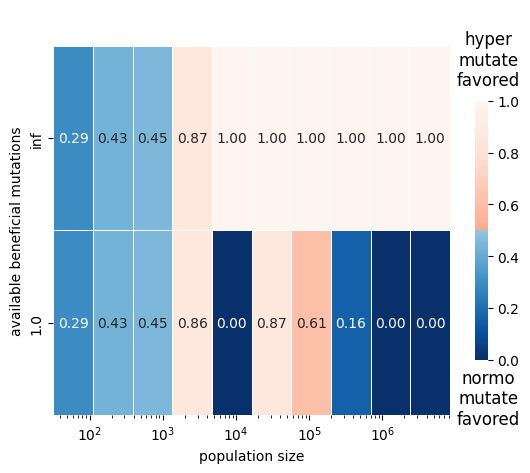

In [ ]:
tp.tee(
    size_fixation_heatmap,
    fixprobs_df=dfxs,
    genotype="mutator",
    index="available beneficial mutations",
    on="population size",
    values="fixation probability",
    teeplot_subdir=teeplot_subdir,
)

## Quality Check: Number Replicates Available

In [ ]:
categories = (
    pl.DataFrame(dfxs)
    .group_by(
        "population size",
    )
    .first()["population size"]
    .sort()
    .cast(pl.String)
    .to_list()
)
categories

In [ ]:
dfy = pl.DataFrame(dfxs).with_columns(
    pl.col("population size")
    .cast(pl.String)
    .cast(pl.Enum(categories))
    .alias("population size cat"),
)
display(dfy.describe()), display(dfy.head()), display(dfy.tail())

teeplots/wse-5050-spatial2d-32atile-infben-traits/col=available-beneficial-mutations+hue=genotype+kind=hist+multiple=dodge+viz=displot+x=population-size-cat+ext=.pdf
teeplots/wse-5050-spatial2d-32atile-infben-traits/col=available-beneficial-mutations+hue=genotype+kind=hist+multiple=dodge+viz=displot+x=population-size-cat+ext=.png


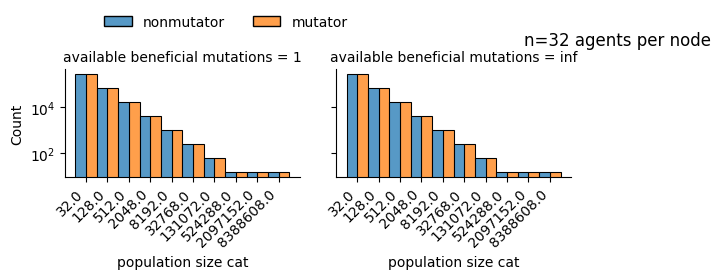

In [ ]:
tp.tee(
    sns.displot,
    data=dfy.to_pandas(),
    x="population size cat",
    hue="genotype",
    hue_order=["nonmutator", "mutator"],
    col="available beneficial mutations",
    aspect=1.5,
    col_wrap=3,
    height=2,
    kind="hist",
    multiple="dodge",
    teeplot_outexclude="post",
    teeplot_postprocess=f"""
teed.set(yscale='log')
teed.figure.suptitle("n={apn} agents per node", x=0.63, y=1.02)
teed.set_titles(col_template='{{col_var}} = {{col_name:.0f}}')
for ax in teed.axes.flat:
    for label in ax.get_xticklabels():
        label.set_rotation(45)
        label.set_ha("right")
sns.move_legend(
    teed, "lower center",
    bbox_to_anchor=(0.25, 0.97),
    frameon=False,
    ncol=2,
    title=None,
)
""",
    teeplot_subdir=teeplot_subdir,
)

## Quality Check: Has Reached Fixation?

In [ ]:
dfxs_ = dfxs[dfxs["genotype"] == "mutator"].copy().reset_index(drop=True)

In [ ]:
dfxs_["neither fixed"] = (dfxs_["fixation probability"] != 1.0) & (
    dfxs_["fixation probability"] != 0.0
)
any_unfixed = dfxs_["neither fixed"].any()
any_unfixed

np.False_

teeplots/wse-5050-spatial2d-32atile-infben-traits/hue=genotype+kind=scatter+style=genotype+viz=relplot+x=population-size+y=fixation-probability+ext=.pdf
teeplots/wse-5050-spatial2d-32atile-infben-traits/hue=genotype+kind=scatter+style=genotype+viz=relplot+x=population-size+y=fixation-probability+ext=.png


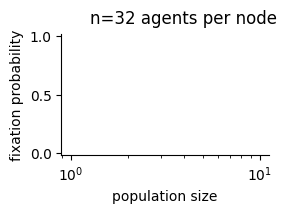

In [ ]:
tp.tee(
    sns.relplot,
    data=dfxs_[dfxs_["neither fixed"]],
    x="population size",
    y="fixation probability",
    hue="genotype",
    hue_order=["nonmutator", "mutator"],
    col=[None, "available beneficial mutations"][int(any_unfixed)],
    style="genotype",
    style_order=["nonmutator", "mutator"],
    aspect=1.5,
    col_wrap=[None, 3][int(any_unfixed)],
    height=2,
    kind="scatter",
    markers=bool(any_unfixed),
    teeplot_outexclude="post",
    teeplot_postprocess=f"""
teed.set(xscale='log', ylim=(-0.02, 1.02))
teed.figure.suptitle("n={apn} agents per node", x=0.63, y=1.02)
teed.set_titles(col_template='{{col_var}} = {{col_name:.0f}}')
try:
    sns.move_legend(
        teed,
        "lower center",
        bbox_to_anchor=(0.25, 0.97),
        frameon=False,
        ncol=2,
        title=None,
    )
except ValueError:
    pass
""",
    teeplot_subdir=teeplot_subdir,
)

teeplots/wse-5050-spatial2d-32atile-infben-traits/col=available-beneficial-mutations+hue=neither-fixed+multiple=fill+palette=pastel2+viz=displot+x=population-size+ext=.pdf
teeplots/wse-5050-spatial2d-32atile-infben-traits/col=available-beneficial-mutations+hue=neither-fixed+multiple=fill+palette=pastel2+viz=displot+x=population-size+ext=.png


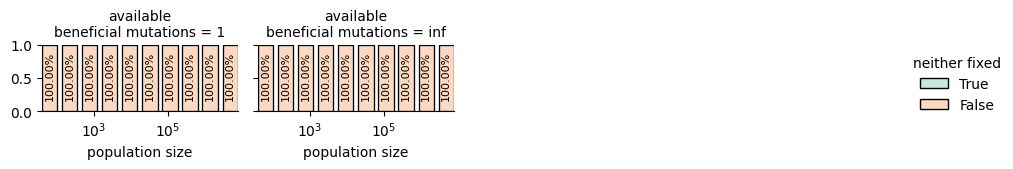

In [ ]:
saveit, teed = tp.tee(
    sns.displot,
    data=dfxs_.reset_index(drop=True),
    x="population size",
    hue="neither fixed",
    hue_order=[True, False],
    col="available\nbeneficial mutations",
    col_wrap=4,
    aspect=1.3,
    height=1.8,
    multiple="fill",
    bins=dfxs_["population size"].nunique(),
    log_scale=(True, False),
    shrink=0.8,
    palette="Pastel2",
    teeplot_callback=True,
    teeplot_subdir=teeplot_subdir,
)

teed.set_titles(col_template="{col_var} = {col_name:.0f}")
teed.set_ylabels("")
# adapted from https://stackoverflow.com/a/68850867
for ax in teed.axes.ravel():
    # add annotations
    for c in ax.containers:
        # custom label calculates percent and add an empty string so 0 value bars don't have a number
        labels = [
            f"{w * 100:0.2f}%" if (w := v.get_height()) > 0.5 else ""
            for v in c
        ]
        ax.bar_label(
            c,
            labels=labels,
            label_type="center",
            fontsize=8,
            rotation=90,
            padding=2,
        )

saveit()